# 08 — Word TF-IDF + Naive Bayes

Compare MultinomialNB and ComplementNB with completed project references on the **exact 25 outer folds from notebook 02**. This changes the classifier while keeping the text-only baseline's TF-IDF representation: word unigrams/bigrams, up to 30,000 terms, min_df=5, max_df=0.5, sublinear TF and English stop words removed. No structured A2 features are supplied, since standardisation could introduce negative inputs invalid for these models.

Both candidates tune smoothing alpha in `[0.1, 1.0, 10.0]`, using three grouped inner folds and mean inner PR-AUC. MultinomialNB learns class priors from each training portion. ComplementNB uses its complement-based default weighting (`norm=False`); no external class weights or oversampling are added. The flagging cutoff maximises F1 on the selected setting's inner out-of-fold predictions. Scores are not assumed calibrated probabilities.

No final test data is read. Learned vocabulary/IDF are fitted separately inside every training split. Completed baseline scores are loaded rather than retrained. Historical baseline provenance limitations from 02 still apply.

**Run entirely in this notebook:** select the project environment and run from the top. `TRAIN_MODELS` defaults to both candidates. Completed folds are saved and reused; an interrupted fold restarts. Set `TRAIN_MODELS=[]` to load saved results only. Do not run two copies against the same output directories simultaneously. Shared source files and other notebooks are unchanged.

In [1]:
import hashlib
import html
import importlib.metadata
import importlib.util
import json
from pathlib import Path
import re
import subprocess
import sys
import tempfile
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/evaluation.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.evaluation import (validate_folds, fold_signature, score_summary, summarise,
                            paired_comparison, select_settings)

from joblib import Memory
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from src.features import build_inputs, make_features

TRAIN_MODELS = ['multinomial_nb', 'complement_nb']
CANDIDATES = ['multinomial_nb', 'complement_nb']
ALPHAS = [0.1, 1.0, 10.0]
THREADS = 2
SEED = 42
INNER_SPLITS = 3
REPORT_DIR = ROOT / 'reports/classifier_naive_bayes'
PREDICTION_DIR = ROOT / 'data/processed/classifier_naive_bayes'


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()

def write_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)

def save_array(path, values):
    path = Path(path)
    temporary = path.with_name(path.name + '.tmp')
    with temporary.open('wb') as stream:
        np.save(stream, values, allow_pickle=False)
    temporary.replace(path)

print('Training enabled for:', TRAIN_MODELS or 'none — load only')

Training enabled for: ['multinomial_nb', 'complement_nb']


## 1. Recover baseline folds and load previous results

The baseline scores and out-of-fold predictions are checked. Additional completed score tables must match the same row/fold fingerprints. The comparison uses mean outer-fold metrics throughout.

In [2]:
BASELINES = {'logreg_text_30k': 'logreg_tf_idf_only', 'logreg_a2_30k': 'logreg_a2'}
NAMES = {'logreg_text_30k': '02: text logistic 30k', 'logreg_a2_30k': '02: A2 logistic 30k',
         'word_char': '04: word + character logistic', 'lightgbm': '03 revised: A2 LightGBM 2k',
         'semantic_minilm': '07: frozen MiniLM fields + logistic',
         'multinomial_nb': '08: word TF-IDF + MultinomialNB',
         'complement_nb': '08: word TF-IDF + ComplementNB'}
train_path = ROOT / 'data/processed/d1_train.csv'
assignment_path = ROOT / 'data/processed/model_cv_assignments.csv'
train = pd.read_csv(train_path)
assert train.job_id.is_unique

y, groups = train.fraudulent.to_numpy(), train.group_id.to_numpy()
assignments = pd.read_csv(assignment_path)
positions = pd.Series(np.arange(len(train)), index=train.job_id)
folds = []
for (repeat, fold), rows in assignments.groupby(['repeat', 'fold'], sort=True):
    if not rows.job_id.is_unique or not rows.job_id.isin(positions.index).all():
        raise ValueError('Invalid job IDs in the saved assignments.')
    val = np.sort(positions.loc[rows.job_id].to_numpy())
    saved_groups = rows.set_index('job_id').group_id
    if not np.array_equal(saved_groups.loc[train.iloc[val].job_id].to_numpy(), groups[val]):
        raise ValueError('Group IDs differ from notebook 02.')
    fit = np.setdiff1d(np.arange(len(train)), val)
    folds.append((int(repeat), int(fold), fit, val))
folds = validate_folds(folds, y, groups)
expected = {(r, f): fold_signature(y, groups, fit, val) for r, f, fit, val in folds}

def validate_scores(scores):
    if scores.duplicated(['repeat', 'fold']).any():
        raise ValueError('Duplicate score rows.')
    actual = {(int(s.repeat), int(s.fold)): s.fold_signature for s in scores.itertuples()}
    if actual != expected:
        raise ValueError('Scores do not match the exact notebook 02 folds and current training rows.')

RESULTS = {}
for key, stem in BASELINES.items():
    scores = pd.read_csv(ROOT / f'reports/tables/model_{stem}_fold_scores.csv')
    validate_scores(scores)
    predictions = pd.read_csv(ROOT / f'data/processed/model_{stem}_oof.csv')
    if predictions.duplicated(['repeat', 'job_id']).any() or len(predictions) != len(train) * len({r for r, *_ in folds}):
        raise ValueError('Baseline predictions are incomplete or duplicated.')
    # Recompute each score from saved probabilities and saved thresholds; no training.
    for r, f, fit, val in folds:
        batch = predictions[predictions.repeat == r].set_index('job_id')
        p = batch.loc[train.iloc[val].job_id, 'probability'].to_numpy()
        row = scores[(scores.repeat == r) & (scores.fold == f)].iloc[0]
        measured = score_summary(y[val], p, threshold=row.threshold)
        for metric in ['pr_auc', 'precision', 'recall', 'f1']:
            if not np.isclose(measured[metric], row[metric]):
                raise ValueError(f'{key}: saved {metric} does not match its predictions.')
    RESULTS[key] = scores
print(f'Validated {len(folds)} saved outer folds on {len(train):,} ads. Reused both 02 baselines.')
display(pd.DataFrame({NAMES[k]: summarise(v, k) for k, v in RESULTS.items()}).T.round(3))
for key, relative in {
    'word_char': 'reports/classifier_word_char/logreg_word_char_fold_scores.csv',
    'lightgbm': 'reports/model_comparison_revised/lightgbm_a2_2k_fold_scores.csv',
    'semantic_minilm': 'reports/classifier_semantic_embeddings/semantic_minilm_fold_scores.csv',
}.items():
    path = ROOT / relative
    if path.exists():
        scores = pd.read_csv(path)
        validate_scores(scores)
        RESULTS[key] = scores
print('Completed references loaded:', [NAMES[k] for k in RESULTS])
X = build_inputs(train)

Validated 25 saved outer folds on 14,439 ads. Reused both 02 baselines.


,pr_auc,roc_auc,precision,recall,f1,share_flagged,false_positive_rate,precision_at_budget,recall_at_budget,precision_top5pct,recall_top5pct,pr_auc_sd
02: text logistic 30k,0.601,0.919,0.624,0.516,0.550,0.043,0.019,0.546,0.568,0.546,0.568,0.085
02: A2 logistic 30k,0.605,0.932,0.611,0.535,0.566,0.043,0.018,0.559,0.581,0.559,0.581,0.094


Completed references loaded: ['02: text logistic 30k', '02: A2 logistic 30k', '04: word + character logistic', '03 revised: A2 LightGBM 2k', '07: frozen MiniLM fields + logistic']


## 2. Fit selected candidates, saving each completed outer fold

A temporary joblib cache reuses fold-fitted TF-IDF transformations between alpha settings. It is cleared after each outer fold, and never fits a vocabulary on outer validation rows. Persistent fold records include settings, scores, inner diagnostics, predictions and hashes. Reused folds are checked against the current data, code, package versions and model settings before loading.

In [3]:
def candidate_spec(key, memory=None):
    if key == 'multinomial_nb':
        classifier = MultinomialNB()
    elif key == 'complement_nb':
        classifier = ComplementNB(norm=False)
    else:
        raise ValueError(key)
    return Pipeline([('features', make_features(blocks=['tfidf'], tfidf_max_features=30000)),
                     ('model', classifier)], memory=memory)

if set(TRAIN_MODELS) - set(CANDIDATES):
    raise ValueError('Unknown TRAIN_MODELS key.')
if SEED != 42 or INNER_SPLITS != 3:
    raise ValueError('Keep the baseline seed 42 and three inner folds.')
context = {
    'training_sha256': sha(train_path), 'assignments_sha256': sha(assignment_path),
    'outer_signatures': {f'{r}:{f}': value for (r,f), value in expected.items()},
    'source_sha256': {name: sha(ROOT/'src'/name) for name in ['features.py', 'evaluation.py']},
    'runner_sha256': digest(''.join(json.loads((ROOT/'notebooks/08_naive_bayes_comparison.ipynb').read_text())['cells'][5]['source'])),
    'versions': {p: importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','scipy','joblib']},
    'seed': SEED, 'inner_splits': INNER_SPLITS, 'review_share': 0.05,
    'threshold_rule': 'inner OOF maximum F1', 'threads': THREADS,
}
for key in CANDIDATES:
    marker_dir = PREDICTION_DIR / key
    plan_path = REPORT_DIR / f'{key}_plan.json'
    grid = {'model__alpha': ALPHAS}
    plan = {**context, 'model': key, 'estimator': repr(candidate_spec(key)), 'grid': grid}
    if plan_path.exists() and json.loads(plan_path.read_text()) != plan:
        raise ValueError(f'{key}: configuration changed. Use new report/prediction directories.')
    if key in TRAIN_MODELS:
        REPORT_DIR.mkdir(parents=True, exist_ok=True)
        marker_dir.mkdir(parents=True, exist_ok=True)
        write_json(plan_path, plan)
    saved_scores, predictions, diagnostics = [], [], []
    print(f'\n{NAMES[key]}', flush=True)
    with tempfile.TemporaryDirectory(prefix='bt4012_nb_') as temporary:
        memory = Memory(temporary, verbose=0)
        pipe = candidate_spec(key, memory)
        for repeat, fold, fit, val in folds:
            marker = marker_dir / f'r{repeat}_f{fold}.json'
            prediction_path = marker_dir / f'r{repeat}_f{fold}_predictions.csv'
            if marker.exists():
                record = json.loads(marker.read_text())
                if not plan_path.exists() or record['plan_sha256'] != digest(plan) or record['score']['fold_signature'] != expected[(repeat,fold)] or record['predictions_sha256'] != sha(prediction_path):
                    raise ValueError('Fold checkpoint mismatch.')
                batch = pd.read_csv(prediction_path)
                if batch.job_id.tolist() != train.iloc[val].job_id.tolist():
                    raise ValueError('Prediction rows differ from saved folds.')
                measured = score_summary(y[val], batch.probability.to_numpy(), threshold=record['score']['threshold'])
                for metric in ['pr_auc','precision','recall','f1']:
                    if not np.isclose(measured[metric], record['score'][metric]):
                        raise ValueError('Cached metrics differ from predictions.')
                row, inner_records = record['score'], record['inner']
                print(f'Reused repeat {repeat+1}, fold {fold+1}', flush=True)
            elif key in TRAIN_MODELS:
                started = time.perf_counter()
                with threadpool_limits(limits=THREADS):
                    selection = select_settings(lambda: pipe, X.iloc[fit], y[fit], groups[fit], grid,
                        inner_splits=INNER_SPLITS, seed=SEED + repeat*1000 + fold)
                    fitted = clone(pipe).set_params(**selection.params).fit(X.iloc[fit], y[fit])
                    probabilities = fitted.predict_proba(X.iloc[val])[:,1]
                row = score_summary(y[val], probabilities, threshold=selection.threshold)
                row.update(repeat=repeat, fold=fold, train_rows=len(fit), val_rows=len(val),
                    val_fraud=int(y[val].sum()), selected_params=selection.params,
                    selection_pr_auc=float(selection.candidates.mean_inner_pr_auc.max()),
                    fold_signature=expected[(repeat,fold)])
                row = json.loads(pd.Series(row).to_json(double_precision=15))
                inner_records = json.loads(selection.candidates.assign(repeat=repeat,fold=fold).to_json(orient='records'))
                batch = pd.DataFrame({'repeat':repeat,'fold':fold,'job_id':train.iloc[val].job_id.to_numpy(),
                    'probability':probabilities,'threshold':selection.threshold})
                temporary_file = prediction_path.with_suffix('.tmp')
                batch.to_csv(temporary_file,index=False)
                temporary_file.replace(prediction_path)
                write_json(marker, {'plan_sha256':digest(plan),'score':row,
                    'predictions_sha256':sha(prediction_path),'inner':inner_records})
                print(f'Repeat {repeat+1}, fold {fold+1}: PR-AUC {row["pr_auc"]:.3f}, '
                      f'alpha {selection.params["model__alpha"]}, {time.perf_counter()-started:.1f}s',flush=True)
                memory.clear(warn=False)
            else:
                continue
            saved_scores.append(row)
            predictions.append(batch)
            diagnostics.extend(inner_records)
    if len(saved_scores) == len(folds):
        scores = pd.DataFrame(saved_scores)
        validate_scores(scores)
        REPORT_DIR.mkdir(parents=True,exist_ok=True)
        RESULTS[key] = scores
        export = scores.copy()
        export['selected_params'] = export.selected_params.map(lambda value:json.dumps(value,sort_keys=True))
        path = REPORT_DIR / f'{key}_fold_scores.csv'
        export.to_csv(path,index=False)
        pd.concat(predictions,ignore_index=True).to_csv(PREDICTION_DIR/f'{key}_predictions.csv',index=False)
        pd.DataFrame(diagnostics).to_csv(REPORT_DIR/f'{key}_inner_settings.csv',index=False)
        write_json(REPORT_DIR/f'{key}_complete.json',{'model':key,'folds':len(scores),'scores_sha256':sha(path)})
        print(f'Completed {NAMES[key]}: {len(scores)} folds',flush=True)
    else:
        print(f'Pending {key}: {len(saved_scores)}/{len(folds)} folds complete.')


08: word TF-IDF + MultinomialNB


Repeat 1, fold 1: PR-AUC 0.479, alpha 0.1, 22.3s


Repeat 1, fold 2: PR-AUC 0.742, alpha 0.1, 20.9s


Repeat 1, fold 3: PR-AUC 0.473, alpha 0.1, 21.3s


Repeat 1, fold 4: PR-AUC 0.666, alpha 0.1, 21.0s


Repeat 1, fold 5: PR-AUC 0.431, alpha 0.1, 20.6s


... (44 outputs left out)

Repeat 5, fold 3: PR-AUC 0.404, alpha 0.1, 20.5s


Repeat 5, fold 4: PR-AUC 0.655, alpha 0.1, 20.6s


Repeat 5, fold 5: PR-AUC 0.648, alpha 0.1, 20.3s


Completed 08: word TF-IDF + ComplementNB: 25 folds


## 3. Performance and paired differences

All candidates use the same outer folds. PR-AUC is the primary metric; inspect F1, fraud recall and top-5% review outcomes too. Approximate paired intervals are exploratory and not adjusted for all comparisons. Scores are not assumed calibrated fraud probabilities. No final fitted production model is selected or exported.

Comparison: COMPLETE


,pr_auc,precision,recall,f1,precision_top5pct,recall_top5pct
03 revised: A2 LightGBM 2k,0.614,0.587,0.543,0.535,0.537,0.558
04: word + character logistic,0.609,0.624,0.516,0.547,0.550,0.571
02: A2 logistic 30k,0.605,0.611,0.535,0.566,0.559,0.581
02: text logistic 30k,0.601,0.624,0.516,0.550,0.546,0.568
08: word TF-IDF + MultinomialNB,0.560,0.556,0.508,0.507,0.507,0.526
08: word TF-IDF + ComplementNB,0.560,0.561,0.505,0.507,0.507,0.526
07: frozen MiniLM fields + logistic,0.521,0.449,0.560,0.489,0.499,0.518


,candidate,reference,metric,mean_diff,se,low,high,share_folds_a_better
0,08: word TF-IDF + MultinomialNB,02: text logistic 30k,pr_auc,-0.042,0.042,-0.126,0.043,0.44
4,08: word TF-IDF + MultinomialNB,02: A2 logistic 30k,pr_auc,-0.045,0.077,-0.200,0.110,0.52
8,08: word TF-IDF + MultinomialNB,04: word + character logistic,pr_auc,-0.050,0.042,-0.134,0.034,0.28
12,08: word TF-IDF + MultinomialNB,03 revised: A2 LightGBM 2k,pr_auc,-0.055,0.084,-0.223,0.114,0.52
16,08: word TF-IDF + ComplementNB,02: text logistic 30k,pr_auc,-0.042,0.042,-0.126,0.043,0.44
20,08: word TF-IDF + ComplementNB,02: A2 logistic 30k,pr_auc,-0.045,0.077,-0.200,0.110,0.52
24,08: word TF-IDF + ComplementNB,04: word + character logistic,pr_auc,-0.050,0.042,-0.134,0.034,0.28
28,08: word TF-IDF + ComplementNB,03 revised: A2 LightGBM 2k,pr_auc,-0.055,0.084,-0.223,0.114,0.52


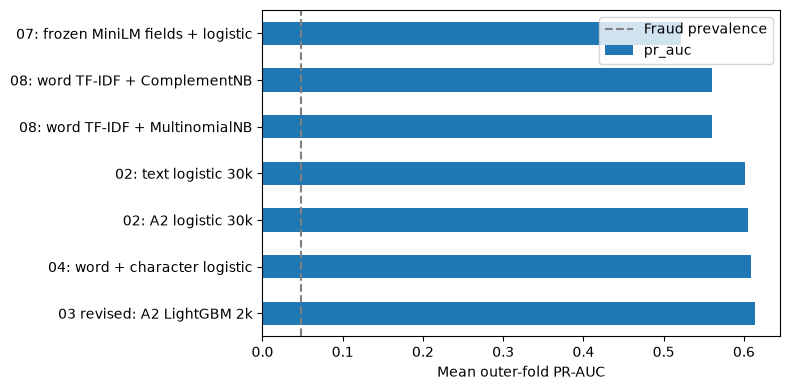

No reserved test data was read.


In [4]:
missing = [key for key in CANDIDATES if key not in RESULTS]
print('Comparison:', 'COMPLETE' if not missing else f'PARTIAL: {missing}')
summary = pd.DataFrame({NAMES[key]:summarise(value,key) for key,value in RESULTS.items()}).T.sort_values('pr_auc',ascending=False)
display(summary[['pr_auc','precision','recall','f1','precision_top5pct','recall_top5pct']].round(3))
REPORT_DIR.mkdir(parents=True,exist_ok=True)
summary.to_csv(REPORT_DIR/'comparison_summary.csv')
rows=[]
for key in CANDIDATES:
    if key not in RESULTS:
        continue
    for reference in ['logreg_text_30k','logreg_a2_30k','word_char','lightgbm']:
        if reference not in RESULTS:
            continue
        for metric in ['pr_auc','f1','recall','precision_top5pct']:
            rows.append({'candidate':NAMES[key],'reference':NAMES[reference],'metric':metric,
                         **paired_comparison(RESULTS[key],RESULTS[reference],metric)})
paired=pd.DataFrame(rows)
if not paired.empty:
    display(paired[paired.metric.eq('pr_auc')].round(3))
    paired.to_csv(REPORT_DIR/'paired_differences.csv',index=False)
ax=summary.pr_auc.plot.barh(figsize=(8,4),xlabel='Mean outer-fold PR-AUC')
ax.axvline(y.mean(),color='grey',linestyle='--',label='Fraud prevalence')
ax.legend()
plt.tight_layout()
plt.show()
print('No reserved test data was read.')